# 1. Imports

In [1]:
import os
import glob 
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torchaudio
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models 

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

torch: 2.10.0+cu128
CUDA available: True


In [2]:
if not torch.cuda.is_available():
    print("[WARNING] No GPU detected. Go to Settings (right panel) -> Accelerator -> GPU, "
          "then restart the session, or training will be very slow.")

In [3]:
DATA_DIR = "/kaggle/input/datasets/mishbhaul/pre-processed-indian-folk-music"
OUTPUT_DIR = "/kaggle/working/"
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "efficientnet_b0.pt")

# 2. Configs

In [4]:
TARGET_FRAMES = 128     
IMG_SIZE = 224

ARCH = "efficientnet_b1"     
EPOCHS = 5
BATCH_SIZE = 16
LR = 1e-4
VAL_SPLIT = 0.2
FREEZE_BACKBONE = False  

# 3. Loading the Dataset

In [5]:
import os
import glob

for cls in os.listdir(DATA_DIR):
    cls_dir = os.path.join(DATA_DIR, cls, cls)

    npy = glob.glob(os.path.join(cls_dir, "*_melspec.npy"))[0]

    size = os.path.getsize(npy) / (1024**3)

    print(f"{cls:20s} {size:.2f} GB")

Bihu                 1.74 GB
Bauls                1.25 GB
Garba                1.93 GB
Maand                2.09 GB
Gidha                1.16 GB
Bhavageethe          1.70 GB
Lavani               1.53 GB
Sufi                 2.41 GB
Kajri                1.80 GB
Naatupura_Paatu      0.48 GB
UttaraKhandi         1.11 GB
Sohar                1.91 GB
Bhatiali             1.51 GB
Veeragase            0.96 GB
Tamang_selo          2.31 GB


In [6]:
def load_style_folders_with_songs(data_dir):
    """
    Load every class folder's *_melspec.npy array plus its song labels.

    Expected structure:
    DATA_DIR/
        Bauls/
            Bauls/
                Bauls_melspec.npy
                Bauls.csv
        Bhajans/
            Bhajans/
                Bhajans_melspec.npy
                Bhajans.csv
        ...
    """

    class_names = sorted(
        d for d in os.listdir(data_dir)
        if os.path.isdir(os.path.join(data_dir, d))
    )

    if not class_names:
        raise RuntimeError(f"No class folders found in {data_dir}")

    X, y, songs = [], [], []

    for label, cls in tqdm(
    enumerate(class_names),
    total=len(class_names),
    desc="Loading classes"
):

        # Outer class folder
        outer_dir = os.path.join(data_dir, cls)

        # Inner folder (same name as class)
        cls_dir = os.path.join(outer_dir, cls)

        if not os.path.isdir(cls_dir):
            print(f"[WARN] Missing inner folder: {cls_dir}")
            continue

        # Find spectrogram
        npy_files = glob.glob(os.path.join(cls_dir, "*_melspec.npy"))

        if not npy_files:
            print(f"[WARN] No *_melspec.npy found in {cls_dir}")
            continue

        arr = np.load(npy_files[0])

        if arr.ndim == 2:
            arr = arr[np.newaxis, ...]
        elif arr.ndim != 3:
            raise ValueError(f"Unexpected shape {arr.shape}")

        # Find CSV
        csv_files = glob.glob(os.path.join(cls_dir, "*.csv"))

        if csv_files:
            meta = pd.read_csv(csv_files[0])

            if "song" in meta.columns:
                song_col = meta["song"].astype(str).tolist()
            else:
                print(f"[WARN] 'song' column missing in {csv_files[0]}")
                song_col = [f"{cls}_{i}" for i in range(len(arr))]
        else:
            print(f"[WARN] No CSV found in {cls_dir}")
            song_col = [f"{cls}_{i}" for i in range(len(arr))]

        if len(song_col) != len(arr):
            print(f"[WARN] {cls}: {len(song_col)} metadata rows vs {len(arr)} samples")

        for i, sample in enumerate(arr):
            X.append(sample.astype(np.float32))
            y.append(label)
            songs.append(song_col[i] if i < len(song_col) else f"{cls}_{i}")

    print(f"Loaded {len(X)} samples across {len(class_names)} classes.")
    print("Classes:", class_names)

    return X, y, songs, class_names


# Load dataset
X, y, songs, CLASS_NAMES = load_style_folders_with_songs(DATA_DIR)
NUM_CLASSES = len(CLASS_NAMES)

print("Example sample shape:", X[0].shape)

Loading classes:   0%|          | 0/15 [00:00<?, ?it/s]

Loaded 385543 samples across 15 classes.
Classes: ['Bauls', 'Bhatiali', 'Bhavageethe', 'Bihu', 'Garba', 'Gidha', 'Kajri', 'Lavani', 'Maand', 'Naatupura_Paatu', 'Sohar', 'Sufi', 'Tamang_selo', 'UttaraKhandi', 'Veeragase']
Example sample shape: (128, 130)


# 4. EDA

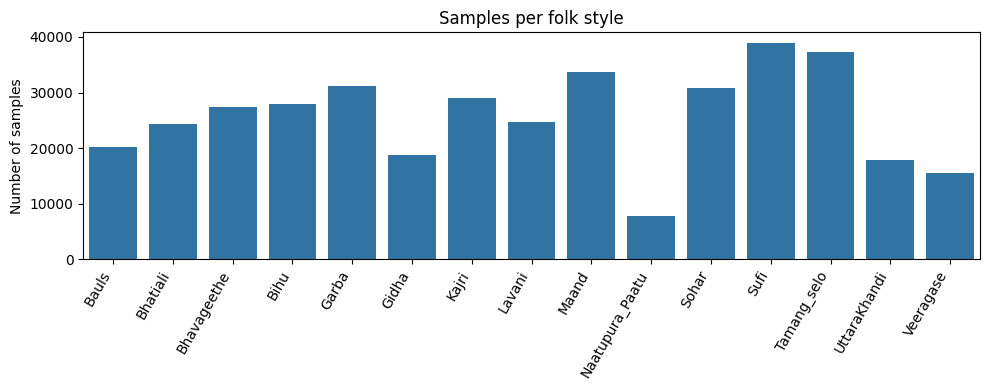

[NOTE] Noticeable class imbalance. Consider class_weight in the loss function, or oversampling the rarer styles.


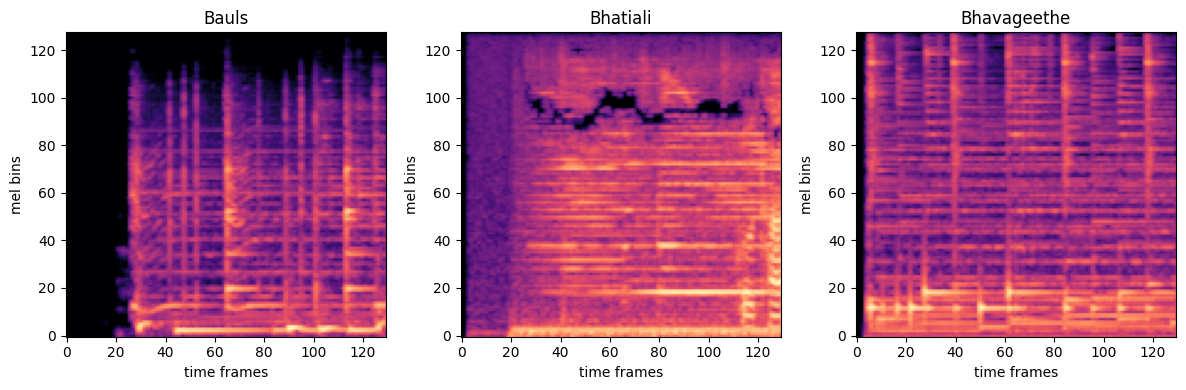

In [13]:
counts = np.bincount(y, minlength=NUM_CLASSES)

plt.figure(figsize=(10, 4))
sns.barplot(x=CLASS_NAMES, y=counts)
plt.xticks(rotation=60, ha="right")
plt.ylabel("Number of samples")
plt.title("Samples per folk style")
plt.tight_layout()
plt.show()

if counts.max() > 2 * counts.min():
    print("[NOTE] Noticeable class imbalance. Consider class_weight in the loss "
          "function, or oversampling the rarer styles.")



n_show = min(3, NUM_CLASSES)
fig, axes = plt.subplots(1, n_show, figsize=(4 * n_show, 4))

for i in range(n_show):
    idx = y.index(i)  # first sample belonging to class i
    axes[i].imshow(X[idx], origin="lower", aspect="auto", cmap="magma")
    axes[i].set_title(CLASS_NAMES[i])
    axes[i].set_xlabel("time frames")
    axes[i].set_ylabel("mel bins")

plt.tight_layout()
plt.show()

# 5. preprocessing functions

In [14]:
def standardize(spec):
    return (spec - spec.mean()) / (spec.std() + 1e-6)

def fix_length(spec, target_frames=TARGET_FRAMES):
    n_mels, n_frames = spec.shape
    if n_frames == target_frames:
        return spec
    if n_frames > target_frames:
        start = (n_frames - target_frames) // 2
        return spec[:, start:start + target_frames]
    pad_total = target_frames - n_frames
    pad_left = pad_total // 2
    pad_right = pad_total - pad_left
    return np.pad(spec, ((0, 0), (pad_left, pad_right)), mode="constant")

def spec_augment(spec):
    spec = spec.copy()
    n_mels, n_frames = spec.shape

    f0 = np.random.randint(0, max(1, n_mels - 10))
    spec[f0:f0 + 10, :] = 0.0   # frequency mask

    t0 = np.random.randint(0, max(1, n_frames - 15))
    spec[:, t0:t0 + 15] = 0.0   # time mask

    return spec

# 6. Visual sanity check: original vs. standardized+augmented, side by side

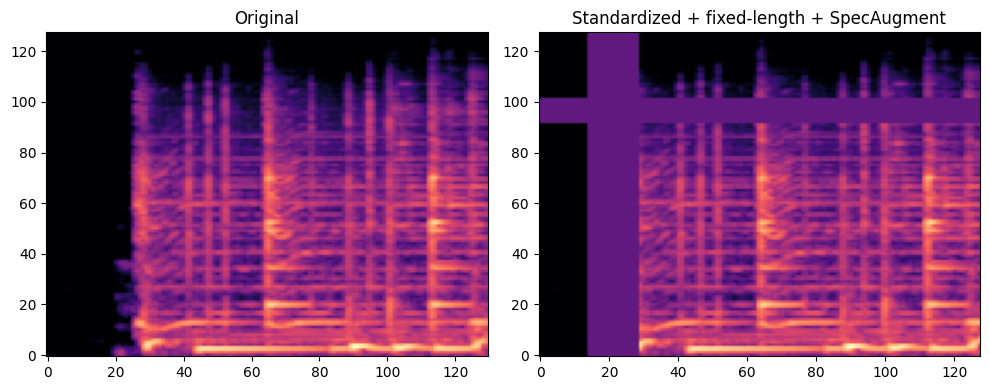

In [15]:
sample = X[0]
augmented = spec_augment(fix_length(standardize(sample)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(sample, origin="lower", aspect="auto", cmap="magma")
axes[0].set_title("Original")
axes[1].imshow(augmented, origin="lower", aspect="auto", cmap="magma")
axes[1].set_title("Standardized + fixed-length + SpecAugment")
plt.tight_layout()
plt.show()

In [16]:
class MelSpecDataset(Dataset):
    def __init__(self, X, y, train=False):
        self.X = X
        self.y = y
        self.train = train

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        spec = self.X[idx]
        spec = standardize(spec)
        spec = fix_length(spec)

        if self.train:
            spec = spec_augment(spec)

        tensor = torch.from_numpy(spec).unsqueeze(0).unsqueeze(0)  # (1,1,n_mels,T)
        tensor = F.interpolate(
            tensor, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False
        ).squeeze(0)                      # (1, IMG_SIZE, IMG_SIZE)
        tensor = tensor.repeat(3, 1, 1)     # (3, IMG_SIZE, IMG_SIZE) -- fake "RGB"

        return tensor, self.y[idx]

# 7. Train-Test Split

```python
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=VAL_SPLIT, random_state=SEED, stratify=y
)

train_ds = MelSpecDataset(X_train, y_train, train=True)
val_ds = MelSpecDataset(X_val, y_val, train=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train samples: {len(train_ds)} | Validation samples: {len(val_ds)}")```

In [17]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(
    test_size=VAL_SPLIT,
    random_state=SEED
)

train_idx, val_idx = next(
    gss.split(X, y, groups=songs)
)

X_train = [X[i] for i in train_idx]
y_train = [y[i] for i in train_idx]

X_val = [X[i] for i in val_idx]
y_val = [y[i] for i in val_idx]

train_ds = MelSpecDataset(X_train, y_train, train=True)
val_ds = MelSpecDataset(X_val, y_val, train=False)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# 8. Model : EfficientNet-B0
### *architecture diagram :*


In [21]:
def build_model(arch, num_classes):
    if arch == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif arch == "resnet34":
        model = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif arch == "alexnet":
        model = models.alexnet(weights=models.AlexNet_Weights.IMAGENET1K_V1)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    elif arch == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif arch == "mobilenet_v2":
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif arch == "mobilenet_v3_large":
        model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V1)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    elif arch == "mobilenet_v3_small":
        model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    else:
        raise ValueError(f"Unknown arch '{arch}'")
    return model

def freeze_backbone(model, arch):
    for param in model.parameters():
        param.requires_grad = False
    if arch.startswith("resnet"):
        for param in model.fc.parameters():
            param.requires_grad = True
    elif arch == "alexnet":
        for param in model.classifier[6].parameters():
            param.requires_grad = True
    elif arch == "efficientnet_b0":
        for param in model.classifier[1].parameters():
            param.requires_grad = True
    elif arch == "mobilenet_v2":
        for param in model.classifier[1].parameters():
            param.requires_grad = True
    elif arch in ("mobilenet_v3_large", "mobilenet_v3_small"):
        for param in model.classifier[3].parameters():
            param.requires_grad = True
    return model

model = build_model(ARCH, NUM_CLASSES).to(DEVICE)
if FREEZE_BACKBONE:
    model = freeze_backbone(model, ARCH)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
trainable_params = filter(lambda p: p.requires_grad, model.parameters())
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR,
    weight_decay=1e-4
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='max',
    factor=0.5,
    patience=2
)

n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_trainable:,} / {n_total:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 113MB/s] 


Trainable parameters: 4,026,763 / 4,026,763


In [22]:
def run_epoch(model, loader, criterion, optimizer, device, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    # Progress bar for batches
    pbar = tqdm(
        loader,
        desc="Training" if train else "Validation",
        leave=False
    )

    with torch.set_grad_enabled(train):
        for inputs, labels in pbar:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * inputs.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += inputs.size(0)

            pbar.set_postfix({
                "loss": f"{loss.item():.4f}",
                "acc": f"{correct/total:.3f}"
            })

    return total_loss / total, correct / total

In [23]:
train_song_set = {songs[i] for i in train_idx}
val_song_set = {songs[i] for i in val_idx}

print("Common songs:", len(train_song_set & val_song_set))

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_acc = 0.0

for epoch in tqdm(range(EPOCHS), desc="Epochs"):

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE,
        train=True
    )

    val_loss, val_acc = run_epoch(
        model,
        val_loader,
        criterion,
        optimizer,
        DEVICE,
        train=False
    )

    scheduler.step(val_acc)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f} "
        f"train_acc={train_acc:.3f} | "
        f"val_loss={val_loss:.4f} "
        f"val_acc={val_acc:.3f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        counter = 0
        torch.save(model.state_dict(), CHECKPOINT_PATH)

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict() if scheduler is not None else None,
        "best_val_acc": best_val_acc,
        "history": history,
    }
    torch.save(checkpoint, "checkpoint.pth")

print(f"\nBest validation accuracy: {best_val_acc:.3f}")
print(f"Best checkpoint saved to: {CHECKPOINT_PATH}")

Common songs: 0


Epochs:   0%|          | 0/5 [00:00<?, ?it/s]

Training:   0%|          | 0/19437 [00:00<?, ?it/s]

Validation:   0%|          | 0/4660 [00:00<?, ?it/s]

Epoch 01/5 | train_loss=0.7989 train_acc=0.922 | val_loss=1.4322 val_acc=0.735


...

Validation:   0%|          | 0/4660 [00:00<?, ?it/s]

Epoch 04/5 | train_loss=0.6001 train_acc=0.990 | val_loss=1.3288 val_acc=0.753


Training:   0%|          | 0/19437 [00:00<?, ?it/s]

Validation:   0%|          | 0/4660 [00:00<?, ?it/s]

Epoch 05/5 | train_loss=0.5969 train_acc=0.991 | val_loss=1.3382 val_acc=0.760

Best validation accuracy: 0.760
Best checkpoint saved to: /kaggle/working/efficientnet_b0.pt


# 9. Evaluation & Confusion Metric

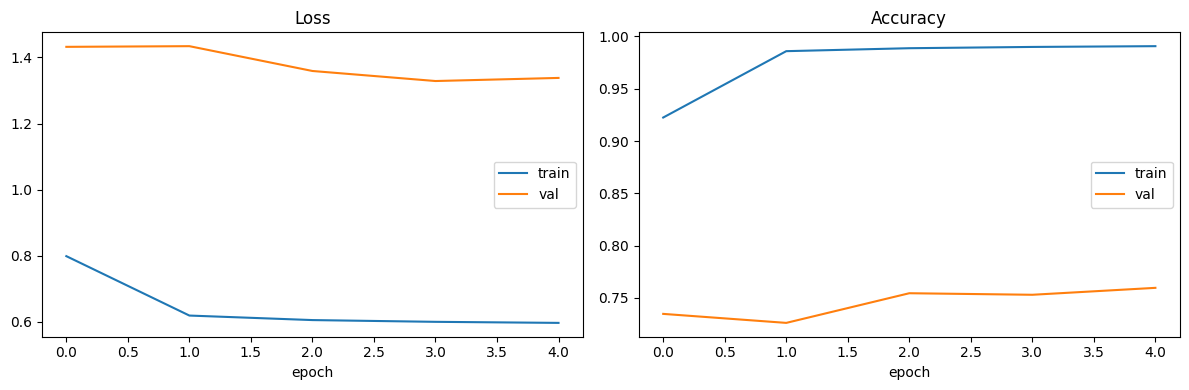

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [25]:
model.load_state_dict(torch.load(CHECKPOINT_PATH))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        outputs = model(inputs.to(DEVICE))
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

                 precision    recall  f1-score   support

          Bauls       0.54      0.39      0.46      4697
       Bhatiali       0.50      0.71      0.59      3212
    Bhavageethe       0.78      0.68      0.73      5973
           Bihu       0.75      0.86      0.80      5732
          Garba       0.96      0.85      0.90      7850
          Gidha       0.94      0.68      0.79      4131
          Kajri       0.75      0.51      0.60      4588
         Lavani       0.82      0.81      0.82      5198
          Maand       0.81      0.88      0.84      6910
Naatupura_Paatu       0.26      0.37      0.31      1423
          Sohar       0.91      0.99      0.95      5308
           Sufi       0.74      0.55      0.63      5162
    Tamang_selo       0.87      0.93      0.90      7489
   UttaraKhandi       0.48      0.81      0.61      2803
      Veeragase       0.75      0.87      0.81      4079

       accuracy                           0.76     74555
      macro avg       0.72   

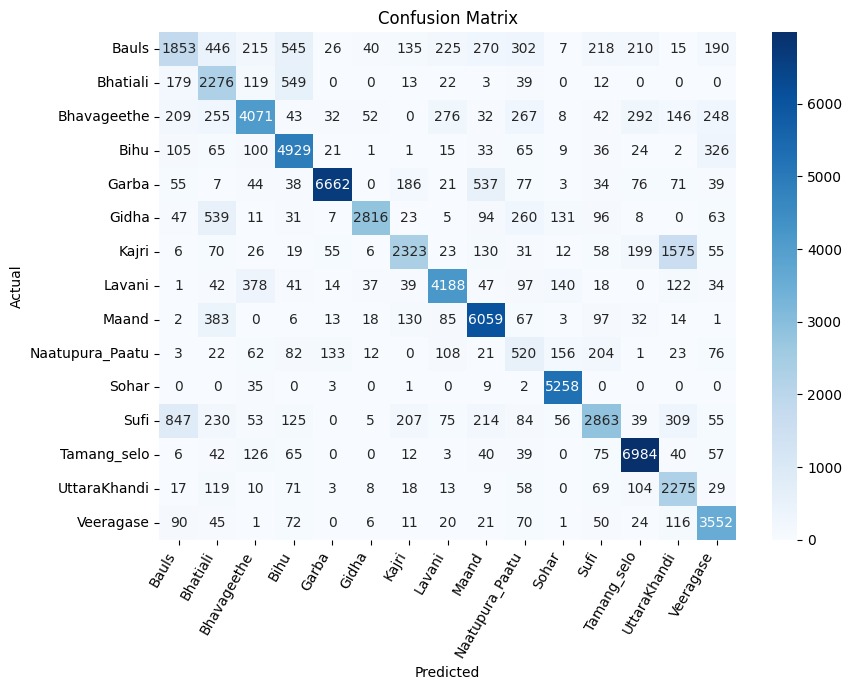

In [26]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

In [29]:
import torch
import torch.nn as nn
from torchvision import models

# 🔧 CUSTOMIZE: same number of classes you trained with originally
NUM_CLASSES = 15

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.efficientnet_b0(weights=None)  # weights=None -> we'll load OUR trained weights next, not ImageNet ones
model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.to(device)

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [30]:
checkpoint_path = "/kaggle/working/efficientnet_b0.pt"
checkpoint = torch.load(checkpoint_path, map_location=device)

start_epoch = 6          # default assumption: you finished epoch 5, so resume at 6
optimizer_state = None

if isinstance(checkpoint, nn.Module):
    # Case A: the WHOLE model object was saved (torch.save(model, path))
    model = checkpoint.to(device)
    print("Loaded a full saved model object.")

elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    # Case B: a full checkpoint dict was saved
    # e.g. torch.save({"model_state_dict":..., "optimizer_state_dict":..., "epoch":...}, path)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer_state = checkpoint.get("optimizer_state_dict")
    start_epoch = checkpoint.get("epoch", 5) + 1
    print(f"Loaded full checkpoint dict. Resuming from epoch {start_epoch}.")

else:
    # Case C: just model.state_dict() was saved
    model.load_state_dict(checkpoint)
    print(f"Loaded weights only (state_dict). Assuming resume from epoch {start_epoch}.")

print(model.__class__.__name__, "ready on", device)

Loaded weights only (state_dict). Assuming resume from epoch 6.
EfficientNet ready on cuda


In [31]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)  # 🔧 CUSTOMIZE: match your original LR

if optimizer_state is not None:
    optimizer.load_state_dict(optimizer_state)
    print("Optimizer momentum/state restored — training will continue smoothly.")
else:
    print("No optimizer state found in this file — optimizer starts fresh (totally fine).")

criterion = nn.CrossEntropyLoss()

No optimizer state found in this file — optimizer starts fresh (totally fine).


In [32]:
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    for images, labels in tqdm(loader, desc="Validating", leave=False):
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total


EXTRA_EPOCHS = 5
end_epoch = start_epoch + EXTRA_EPOCHS - 1
best_val_acc = 0.0  # 🔧 if you tracked this before, set it to your previous best instead of 0.0

for epoch in range(start_epoch, end_epoch + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    print(f"Epoch {epoch}/{end_epoch} | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        # Save as a full checkpoint this time — makes future resuming painless
        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch,
            "val_acc": val_acc,
        }, "/kaggle/working/efficientnet_b0_checkpoint.pt")
        print(f"  -> new best model saved (val_acc={val_acc:.4f})")

print(f"\nDone. Best validation accuracy across all epochs so far: {best_val_acc:.4f}")

Training:   0%|          | 0/19437 [00:00<?, ?it/s]

KeyboardInterrupt: 